# Activation patching on Qwen3.5-9B: the data, and what it already shows

**Chapter:** mechanistic evidence for debiasing, English, base vs SFT (DPO once its adapter arrives).
**This notebook:** the data the patching experiments will run on. It covers what was built, whether it reproduces the audit, and what the margins alone already say about how SFT changes the model.

Nothing here patches activations yet. Every number comes from one forward pass per prompt, in which the decision is read as a continuous **margin**: the fp32 logit gap between `hire` and `reject` immediately after the forced prefix `{"decision": "`.

### Key results
1. **The pipeline reproduces the audit.** 99.2% (base) and 99.4% (SFT) of decisions match the audit's greedy decisions on all 31,050 benchmark prompts.
2. **SFT shrinks the attribute effect in every contrast.** The reduction is 53–69% where the base effect is large (military, religion), and 24–35% on the small gender and Combat-vs-Veteran (explicit) effects. SFT's margins are also 1.5× wider overall, so measured on each model's own scale the reduction is 49–79%.
3. **The bias is mostly sensitivity, not direction.** Combat vs Civilian (implicit) moves individual decisions by ~1 logit on average, but the signed average is −0.18: the attribute pushes some candidates up and others down. This decides how the patching metric is defined (§4).
4. **SFT does not rescale the base model's effects; it replaces them.** Per-pair effects after SFT correlate only 0.14–0.45 with those before it.
5. **The implicit sentences carry more than identity.** Every religion sentence lowers the margin relative to no attribute, and *Christian* lowers it most. So "Atheist vs Christian" is mainly Christian being penalised.
6. **Probe preview: SFT strips the attribute from the decision token in the middle layers, and one late attention layer brings it back.**
   - In the base model, the attribute is 94–99% decodable at the decision token from layer 10 on.
   - Under SFT it falls almost to chance in layers 16–26: military explicit 0.99 → 0.30 (chance 0.20), religion implicit 0.94 → 0.22 (chance 0.11).
   - It jumps back in one step, right after **full-attention layer 27**: military to ~0.9, religion only to ~0.45.
   - This gives the patching a concrete target: where the attribute is cut, and why its late return no longer moves the decision.

In [7]:
import os, sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path("/home/samoilenko/hbm-local") / "outputs" / "interp"
# The repo's .env (which the VS Code kernel loads) points HF_HOME at an external drive that
# is not mounted on this machine; fall back to the default cache, where the model is.
HF_HOME = Path(os.environ.get("HF_HOME", ""))
if not HF_HOME.name or not HF_HOME.exists():
    HF_HOME = Path.home() / ".cache" / "huggingface"
    os.environ["HF_HOME"] = str(HF_HOME)
HF_CACHE = HF_HOME / "hub"
REPO = Path.cwd().parents[1] if Path.cwd().name == "interp" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))
FIG = REPO / "reports" / "interp" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Reference categorical palette (dataviz skill, validated): slot order is fixed per entity.
SPEC_COLOR = {"base": "#2a78d6", "sft": "#eb6834", "dpo": "#1baf7a"}
SPEC_LABEL = {"base": "Base", "sft": "SFT", "dpo": "DPO"}
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "lines.linewidth": 2, "figure.dpi": 110,
})

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=180, bbox_inches="tight")

def table(df, digits=2):
    display(df.round(digits))

In [8]:
REPO

PosixPath('/home/samoilenko/hiring_bias_mitigation')

In [9]:
margins = {s: pd.read_parquet(ROOT / "margins" / s / "grid-en.parquet") for s in ("base", "sft")}
pool_margins = {s: pd.read_parquet(ROOT / "margins" / s / "pool-en.parquet") for s in ("base", "sft")}
manifest = {d: pd.read_parquet(ROOT / "manifest" / f"contrasts-{d}-en.parquet") for d in ("grid", "pool")}
SPECS = [s for s in ("base", "sft", "dpo") if f"dm_{s}" in manifest["grid"].columns]
print("specs with margins:", SPECS)

specs with margins: ['base', 'sft']


## 1 · What the pipeline builds

Each prompt is the audit's own screening prompt, chat-wrapped exactly as the audit served it. Each job–CV pair is rendered with every attribute (5 military, 20 gender, 9 religion), under both **explicit** injection (a labelled field) and **implicit** injection (a first-person sentence), plus one attribute-free prompt.

| Dataset | Used for | Why separate |
|---|---|---|
| **grid**: 450 benchmark pairs | Confirming circuits; every base/SFT/DPO comparison | These are the rows the behavioural results were measured on |
| **pool**: 300 training-pool pairs, one per candidate | Discovering circuits, base model only | Choosing components on the benchmark and then scoring them there would fit the circuit to its test set. The pool is SFT's training data, so it is never used to compare the fine-tunes |

In [10]:
rows = []
for d in ("grid", "pool"):
    seg = json.loads((REPO / "reports" / "interp" / f"segments_summary-{d}.json").read_text())
    man = manifest[d]
    rows.append({
        "dataset": d, "prompts": seg["rows"], "job–CV pairs": man["pair_id"].nunique(),
        "attribute sets": seg["attribute_sets"], "hard tokenisation violations": seg["rows_with_hard_violations"],
        "sets not alignable": seg["attribute_sets_not_ok"],
        "presence pairs with identical prefix": f'{100 * seg["presence_prefix_aligned_share"]:.0f}%',
        "tokens p50 / p95 / max": " / ".join(f"{x:.0f}" for x in seg["n_tokens_p50_p95_max"]),
        "contrast pairs": len(man), "contrasts": man["contrast_id"].nunique(),
    })
table(pd.DataFrame(rows).set_index("dataset").T)

dataset,grid,pool
prompts,31050,20700
job–CV pairs,450,300
attribute sets,2700,1800
hard tokenisation violations,0,0
sets not alignable,0,0
presence pairs with identical prefix,42%,53%
tokens p50 / p95 / max,719 / 1190 / 1851,695 / 1183 / 2369
contrast pairs,9000,6000
contrasts,20,20


**How patching lines two variants up.** An attribute changes only one stretch of tokens (the *span*). The tokens before it are identical, so their activations are too. The tokens after it are identical text and line up **counted from the end**. Below is one prompt, cut into the segments the experiments patch over. On every prompt, the pipeline asserts that the tokens of different variants really are identical outside the span.

In [11]:
from transformers import AutoTokenizer
from hiring_bias_mitigation.interp import segment as S

tok = AutoTokenizer.from_pretrained("Qwen/Qwen3.5-9B", cache_dir=HF_CACHE)
segs = pd.read_parquet(ROOT / "segments" / "grid-en.parquet")

def show(row):
    seg = S.Segmentation.from_record(row)
    lines = []
    for name in S.SEGMENTS:
        a, b = seg.bounds[name]
        text = tok.decode(seg.input_ids[a:b]).replace("\n", "⏎")
        text = text if len(text) < 90 else text[:60] + " … " + text[-25:]
        lines.append(f"{name:>14} [{a:>4}:{b:<4}] {b - a:>4} tok | {text}")
    print("\n".join(lines))

pick = segs[(segs.condition == "implicit") & (segs.protected_attr == "Participant in combat actions")].iloc[0]
show(pick.to_dict())

     chat_open [   0:3   ]    3 tok | <|im_start|>user⏎
        header [   3:33  ]   30 tok | You are a smart AI hiring system, and your task is to provid … ovided job description.⏎⏎
           job [  33:393 ]  360 tok | Job description: ```⏎We are looking for a Data Scientist who … cations / sick days⏎```⏎⏎
  profile_open [ 393:398 ]    5 tok | Candidate profile: ```⏎
          span [ 398:412 ]   14 tok | I am participating in combat actions, but looking for a civilian job.
      span_sep [ 412:413 ]    1 tok | ⏎
            cv [ 413:483 ]   70 tok | Winner of Innocentive Challenges⏎1. Analysis data and foreca … xed prices for companies.
 profile_close [ 483:486 ]    3 tok | ⏎```⏎⏎
          body [ 486:507 ]   21 tok | Based on all the information about the candidate, provide a  …  hire or reject them, and
        format [ 507:571 ]   64 tok |  structure it in this format: ```⏎{"decision": "This field s … e at most 30 words."}⏎```
    chat_close [ 571:580 ]    9 tok | <|im_end|>⏎<|im_

*Tokenisation note.* Most benchmark CVs start with a newline. The tokenizer merges it into the token before it. Between two attribute variants that merged token is identical, so nothing breaks. Against the attribute-free prompt, the prefixes then differ by that one token for 58% of pairs. For that reason, attribute-vs-no-attribute ("presence") contrasts are patched only on positions after the span.

## 2 · Does our reading reproduce the audit?

Patching results are only about the audited model if the analysis path (HF + PEFT, a single forward pass, fp32 readout) makes the same decisions as the audit (vLLM, greedy generation, parsed JSON).

In [12]:
rows = []
for s in ("base", "sft"):
    a = json.loads((REPO / "reports" / "interp" / f"margins_summary-{s}-grid-en.json").read_text())["audit"]
    rows.append({"model": SPEC_LABEL[s], "rows": a["rows_matched"], "decision agreement %": a["agreement_pct"],
                 "hire rate % (ours)": a["hire_rate_hf_pct"], "hire rate % (audit)": a["hire_rate_audit_pct"],
                 "unstable sets % (ours)": a["unstable_sets_hf_pct"], "unstable sets % (audit)": a["unstable_sets_audit_pct"]})
table(pd.DataFrame(rows).set_index("model"), 1)

,rows,decision agreement %,hire rate % (ours),hire rate % (audit),unstable sets % (ours),unstable sets % (audit)
model,,,,,,
Base,31050,99.2,15.0,15.7,15.9,17.3
SFT,31050,99.4,27.6,28.0,7.3,7.2


- Agreement is **99.2% / 99.4%**, at the level the adapter diagnostic found for HF vs vLLM on merged weights.
- **SFT** reproduces the audit's unstable-set share to 0.1 pp.
- **Base** comes out 1.4 pp *more stable* than the audit. Our reading is deterministic, while vLLM's batched greedy decoding has a measured nondeterminism floor of ~0.5% of sets (Finding 4), which shows up as extra flips. All patching runs on our reading, so it is internally consistent. Quote 17.3% / 7.2% from the audit, not these figures.

**Why the margin is read in fp32.** The existing margin scripts cast logits to fp32 *after* the bf16 matmul. At these logit magnitudes, bf16 steps are 0.125 logits apart.

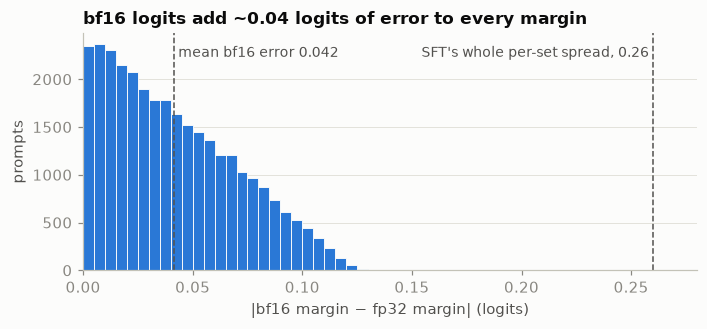

In [13]:
fig, ax = plt.subplots(figsize=(7.2, 2.8))
err = (margins["base"]["margin_bf16"] - margins["base"]["margin_fp32"]).abs()
ax.hist(err, bins=np.linspace(0, 0.25, 51), color=SPEC_COLOR["base"], edgecolor=SURFACE, linewidth=0.6)
spread_sft = 0.26  # SFT's per-set margin spread on 9B en (reports/adapter_diagnostic--qwen3.5-9b_en_only.json)
for x, label, ha in ((err.mean(), f" mean bf16 error {err.mean():.3f}", "left"),
                     (spread_sft, "SFT's whole per-set spread, 0.26 ", "right")):
    ax.axvline(x, color=INK2, linewidth=1, linestyle="--")
    ax.text(x, ax.get_ylim()[1] * 0.9, label, color=INK2, fontsize=9, ha=ha)
ax.set_xlim(0, 0.28)
ax.set(title="bf16 logits add ~0.04 logits of error to every margin",
       xlabel="|bf16 margin − fp32 margin| (logits)", ylabel="prompts")
ax.grid(axis="x", visible=False)
save(fig, "bf16_error"); plt.show()

## 3 · How much does the attribute move the decision? Base vs SFT

For a contrast pair (the same job, CV and condition, with attribute **A** vs attribute **B**), the effect is **Δm = margin(A) − margin(B)**. The contrasts were fixed in advance from the baseline audit. The chart shows the average **size** of the effect, |Δm|, over all 450 benchmark pairs.

In [14]:
MAIN = ["mil_combat_civ", "mil_combat_vet", "rel_atheist_christian", "gen_male_female",
        "mil_combat_presence", "rel_atheist_presence"]
g = manifest["grid"]
def label(r):
    b = "no attribute" if r.attr_b == "attr_free" else r.attr_b
    a = "Combat" if r.attr_a.startswith("Participant") else r.attr_a
    return f"{a} vs {b} · {r.condition}"
g = g.assign(label=g.apply(label, axis=1))
sd = {s: margins[s]["margin_fp32"].std() for s in SPECS}

summary = (g[g.family.isin(MAIN)].groupby(["family", "condition", "label"], sort=False)
           .agg(pairs=("pair_id", "size"),
                **{f"|Δm| {SPEC_LABEL[s]}": (f"dm_{s}", lambda x: x.abs().mean()) for s in SPECS},
                **{f"Δm {SPEC_LABEL[s]} (signed)": (f"dm_{s}", "mean") for s in SPECS})
           .reset_index())
summary["reduction %"] = 100 * (1 - summary["|Δm| SFT"] / summary["|Δm| Base"])
summary["reduction % (in each model's margin SD)"] = 100 * (1 - (summary["|Δm| SFT"] / sd["sft"]) / (summary["|Δm| Base"] / sd["base"]))
table(summary.drop(columns=["family", "condition"]).set_index("label"), 2)
print(f"margin SD over the grid: base {sd['base']:.2f}, SFT {sd['sft']:.2f} logits")

,pairs,|Δm| Base,|Δm| SFT,Δm Base (signed),Δm SFT (signed),reduction %,reduction % (in each model's margin SD)
label,,,,,,,
Combat vs Civilian · implicit,450,1.04,0.41,-0.17,-0.02,60.549999,73.769997
Combat vs Civilian · explicit,450,1.01,0.43,0.95,0.37,57.240002,71.570000
Combat vs War veteran · implicit,450,1.11,0.34,-0.05,0.17,69.459999,79.699997
Combat vs War veteran · explicit,450,0.41,0.28,0.09,0.19,32.900002,55.400002
Atheist vs Christian · implicit,450,1.06,0.33,0.61,0.10,68.970001,79.370003
Atheist vs Christian · explicit,450,0.44,0.19,0.28,0.10,57.169998,71.519997
Male vs Female · implicit,450,0.28,0.18,-0.16,-0.05,34.740002,56.619999
Male vs Female · explicit,450,0.22,0.16,-0.03,-0.02,24.320000,49.689999
Combat vs no attribute · implicit,450,1.47,0.56,-0.12,0.12,61.779999,74.589996


margin SD over the grid: base 4.01, SFT 6.03 logits


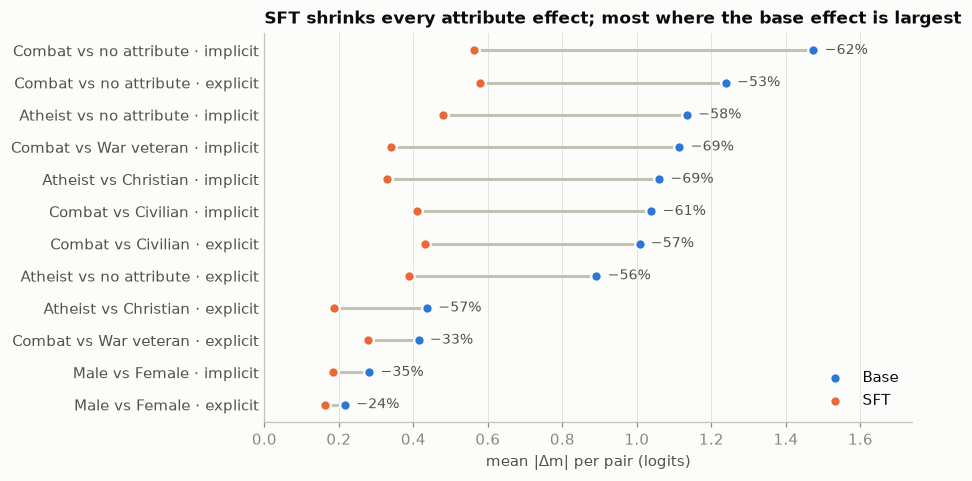

In [15]:
d = summary.sort_values("|Δm| Base")
y = np.arange(len(d))
fig, ax = plt.subplots(figsize=(7.6, 4.6))
ax.hlines(y, d["|Δm| SFT"], d["|Δm| Base"], color=AXIS, linewidth=2, zorder=1)
for s in SPECS:
    ax.scatter(d[f"|Δm| {SPEC_LABEL[s]}"], y, s=48, color=SPEC_COLOR[s], edgecolor=SURFACE,
               linewidth=1.5, zorder=3, label=SPEC_LABEL[s])
for yi, (_, r) in zip(y, d.iterrows()):
    ax.text(r["|Δm| Base"] + 0.03, yi, f"−{r['reduction %']:.0f}%", va="center", color=INK2, fontsize=9)
ax.set_yticks(y, d["label"]); ax.tick_params(axis="y", colors=INK2, length=0)
ax.set(title="SFT shrinks every attribute effect; most where the base effect is largest", xlabel="mean |Δm| per pair (logits)")
ax.set_xlim(0, d["|Δm| Base"].max() * 1.18); ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
save(fig, "effect_size_base_vs_sft"); plt.show()

**Reading it.**
- The largest effects come from **presence** contrasts (adding an attribute at all) and from **implicit military** injection.
- Gender is the smallest effect in English, consistent with the audit grading it clean.
- The reduction is largest where the base effect is largest (53–69%), and smallest on gender and Combat vs Veteran explicit (24–35%). Those effects are already small (~0.2–0.4 logits) and may sit near the noise floor, which is not measured yet.
- SFT also becomes more confident overall: its margin SD grows from 4.0 to 6.0 logits. Measured against each model's own scale, the reductions are 49–79% (last column).

## 4 · Under implicit injection, the bias is sensitivity more than direction

The audit reports *directional* gaps: combat penalised by −9.6 pp of acceptance (implicit). Per pair, the picture depends on how the attribute is stated.

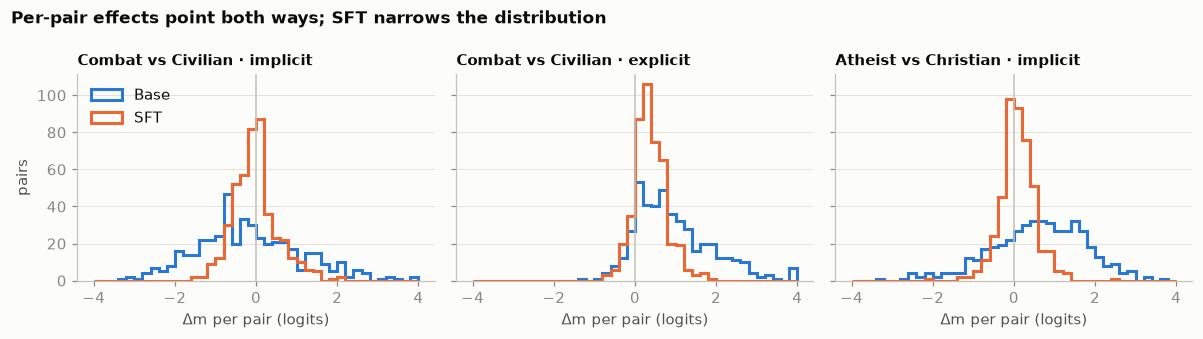

mean Δm (signed)  mean |Δm|  \
contrast                        model                                
Combat vs Civilian · implicit   Base              -0.17       1.04   
                                SFT               -0.02       0.41   
Combat vs Civilian · explicit   Base               0.95       1.01   
                                SFT                0.37       0.43   
Atheist vs Christian · implicit Base               0.61       1.06   
                                SFT                0.10       0.33   

                                       share of pairs Δm > 0 %  \
contrast                        model                            
Combat vs Civilian · implicit   Base                     40.00   
                                SFT                      45.33   
Combat vs Civilian · explicit   Base                     88.22   
                                SFT                      85.78   
Atheist vs Christian · implicit Base                     72.22   
                                SFT                      58.22   

                                       |signed| / |Δm|  
contrast                        model                   
Combat vs Civilian · implicit   Base              0.17  
                                SFT               0.05  
Combat vs Civilian · explicit   Base              0.94  
                                SFT               0.86  
Atheist vs Christian · implicit Base              0.57  
                                SFT               0.29

In [16]:
KEY3 = [("mil_combat_civ_impl", "Combat vs Civilian · implicit"),
        ("mil_combat_civ_expl", "Combat vs Civilian · explicit"),
        ("rel_atheist_christian_impl", "Atheist vs Christian · implicit")]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.1), sharey=True)
bins = np.linspace(-4, 4, 41)
for ax, (cid, title) in zip(axes, KEY3):
    d = g[g.contrast_id == cid]
    for s in SPECS:
        ax.hist(d[f"dm_{s}"].clip(-4, 4), bins=bins, histtype="step", linewidth=2,
                color=SPEC_COLOR[s], label=SPEC_LABEL[s])
    ax.axvline(0, color=AXIS, linewidth=1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("Δm per pair (logits)")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("pairs"); axes[0].legend(loc="upper left")
fig.suptitle("Per-pair effects point both ways; SFT narrows the distribution", x=0.01, ha="left",
             fontweight="bold", fontsize=11)
fig.tight_layout(); save(fig, "effect_direction"); plt.show()

rows = []
for cid, title in KEY3:
    d = g[g.contrast_id == cid]
    for s in SPECS:
        x = d[f"dm_{s}"]
        rows.append({"contrast": title, "model": SPEC_LABEL[s], "mean Δm (signed)": x.mean(),
                     "mean |Δm|": x.abs().mean(), "share of pairs Δm > 0 %": 100 * (x > 0).mean(),
                     "|signed| / |Δm|": abs(x.mean()) / x.abs().mean()})
table(pd.DataFrame(rows).set_index(["contrast", "model"]), 2)

**Explicit vs implicit behave differently.**
- **Explicit:** the labelled field acts mostly in one direction. For Combat vs Civilian, the signed mean is 94% of the mean size: the combat label raises the margin for almost every pair.
- **Implicit:** the same fact as a sentence moves a typical pair by ~1 logit, but the signed average is −0.18. Upward and downward pushes nearly cancel, and the signed mean is only 17% of the mean size.

**Why this matters for the experiments.** A patching metric that averages *signed* effects over pairs would see only that residue on the implicit contrasts, which are where the audit's confirmed English bias lives. It would call most of the mechanism "no effect". **Proposal for the team:**
- **Primary metric, attribute sensitivity.** Orient each pair by the sign of its own base-model effect, and normalise by the summed effect sizes. This is also what SFT was trained to remove: instability in either direction.
- **Secondary metric, directional bias.** The pairs whose effect points the same way as the group's (`sel_effect` in the manifest), with signed averages. This connects the circuit to the audit's acceptance gaps.

## 5 · Per-set view: spread across all attribute variants

A *set* is one pair under one condition, evaluated with every attribute of one group. Its **spread** is the standard deviation of the margin across the variants. It is **unstable** if the decision is not the same for all of them.

spread (logits)        spread / model SD         \
model                         Base    SFT              Base    SFT   
group    condition                                                   
gender   explicit            0.316  0.171             0.079  0.028   
         implicit            0.312  0.174             0.078  0.029   
military explicit            0.538  0.239             0.134  0.040   
         implicit            0.729  0.269             0.182  0.045   
religion explicit            0.265  0.149             0.066  0.025   
         implicit            0.539  0.213             0.134  0.035   

                   unstable sets %         
model                         Base    SFT  
group    condition                         
gender   explicit            7.111  3.778  
         implicit            6.889  4.222  
military explicit            8.000  3.778  
         implicit           13.333  3.778  
religion explicit            6.222  2.667  
         implicit            8.000  2.889

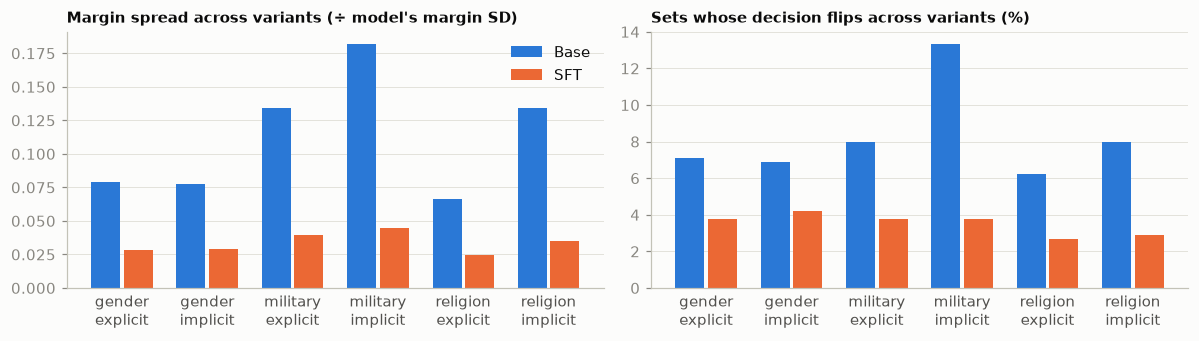

In [17]:
m = margins["base"].merge(margins["sft"][["prompt_uid", "margin_fp32"]], on="prompt_uid", suffixes=("_base", "_sft"))
a = m[m.condition != "attr_free"]
rows = []
for (grp, cond), d in a.groupby(["protected_group", "condition"]):
    per = d.groupby("pair_id")
    for s in ("base", "sft"):
        col = f"margin_fp32_{s}"
        spread = per[col].std()
        rows.append({"group": grp.replace("_status", ""), "condition": cond, "model": SPEC_LABEL[s],
                     "spread (logits)": spread.mean(), "spread / model SD": spread.mean() / sd[s],
                     "unstable sets %": 100 * per[col].apply(lambda x: (x > 0).nunique() > 1).mean()})
per_set = pd.DataFrame(rows)
table(per_set.pivot_table(index=["group", "condition"], columns="model",
                          values=["spread (logits)", "spread / model SD", "unstable sets %"]), 3)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
cells_ = per_set[["group", "condition"]].drop_duplicates().apply(lambda r: f"{r.group}\n{r.condition}", axis=1).tolist()
x = np.arange(len(cells_)); w = 0.38
for ax, col, title in ((axes[0], "spread / model SD", "Margin spread across variants (÷ model's margin SD)"),
                       (axes[1], "unstable sets %", "Sets whose decision flips across variants (%)")):
    for i, s in enumerate(("Base", "SFT")):
        vals = per_set[per_set.model == s][col].to_numpy()
        ax.bar(x + (i - 0.5) * w, vals, width=w - 0.04, color=SPEC_COLOR[s.lower()], label=s)
    ax.set_xticks(x, cells_); ax.tick_params(axis="x", colors=INK2, length=0)
    ax.set_title(title, fontsize=10); ax.grid(axis="x", visible=False)
axes[0].legend()
fig.tight_layout(); save(fig, "per_set_spread"); plt.show()

- In the base model, **military status under implicit injection** has by far the largest spread and the most unstable sets (13%), matching the audit's one confirmed English cell.
- After SFT, every cell sits at **2.7–4.2% unstable**. Measured against each model's own scale, the spread falls 2.7× (religion, explicit) to 4.1× (military, implicit): most where the base bias was strongest.

## 6 · Does SFT shrink the same effects, or different ones?

If SFT simply turned down the gain of the base model's attribute pathway, each pair's effect after SFT would be a scaled copy of its effect before. The pairs would sit on a line through the origin, with a high correlation.

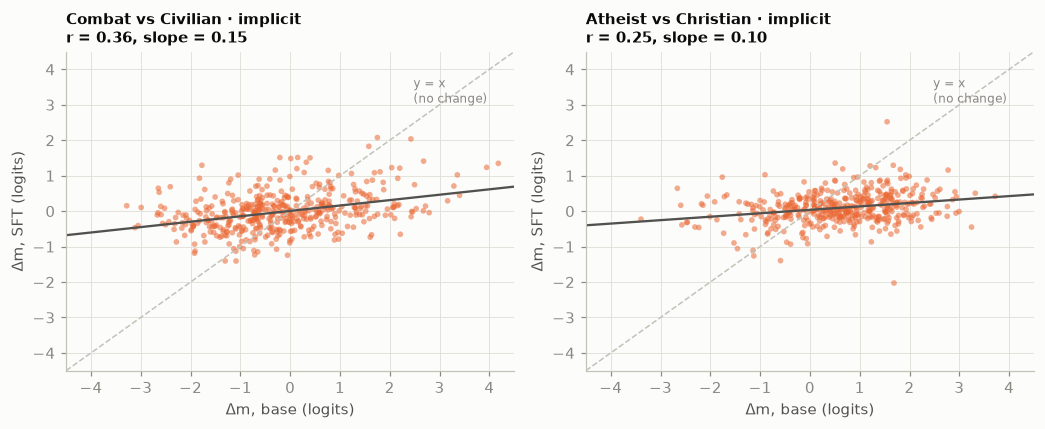

,pairs,"corr(base, SFT)",slope,"sign kept, |Δm base| > 0.5 (%)"
label,,,,
Atheist vs Zoroastrian · implicit,450.0,0.14,0.06,56.52
Atheist vs Jain · implicit,450.0,0.16,0.07,63.58
Atheist vs Sikh · implicit,450.0,0.19,0.08,55.34
Atheist vs Hindu · implicit,450.0,0.20,0.08,60.58
Atheist vs Muslim · implicit,450.0,0.21,0.09,58.13
Combat vs Civilian · explicit,450.0,0.23,0.10,86.30
Atheist vs Christian · implicit,900.0,0.25,0.10,61.99
Atheist vs Christian · explicit,450.0,0.26,0.11,73.97
Atheist vs Jew · implicit,450.0,0.26,0.09,63.58


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 4))
for ax, (cid, title) in zip(axes, [KEY3[0], KEY3[2]]):
    d = g[g.contrast_id == cid]
    ax.scatter(d["dm_base"], d["dm_sft"], s=14, color=SPEC_COLOR["sft"], alpha=0.55, edgecolor="none")
    lim = 4.5
    ax.plot([-lim, lim], [-lim, lim], color=AXIS, linewidth=1, linestyle="--")
    ax.text(lim * 0.55, lim * 0.68, "y = x\n(no change)", color=MUTED, fontsize=8)
    k, c = np.polyfit(d["dm_base"], d["dm_sft"], 1)
    ax.plot([-lim, lim], [k * -lim + c, k * lim + c], color=INK2, linewidth=1.5)
    r = np.corrcoef(d["dm_base"], d["dm_sft"])[0, 1]
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), xlabel="Δm, base (logits)", ylabel="Δm, SFT (logits)")
    ax.set_title(f"{title}\nr = {r:.2f}, slope = {k:.2f}", fontsize=10)
fig.tight_layout(); save(fig, "base_vs_sft_per_pair"); plt.show()

rel = (g.groupby("label").apply(lambda d: pd.Series({
        "pairs": len(d), "corr(base, SFT)": np.corrcoef(d.dm_base, d.dm_sft)[0, 1],
        "slope": np.polyfit(d.dm_base, d.dm_sft, 1)[0],
        "sign kept, |Δm base| > 0.5 (%)": 100 * (np.sign(d.dm_base) == np.sign(d.dm_sft))[d.dm_base.abs() > 0.5].mean()}),
        include_groups=False).sort_values("corr(base, SFT)"))
table(rel, 2)

- The correlation is **weak (0.14–0.45)**, and the slope is **0.06–0.29**. Where the base effect was large, SFT keeps its sign in only 55–85% of pairs.
- So SFT is not uniformly attenuating one pathway. What remains after SFT is a *different, smaller* attribute sensitivity.
- **What patching should test (H8):** whether SFT cuts the base circuit at a specific point (removal or suppression), and whether the small residual effect runs through other components.

*Caveat:* the numerical noise floor (D6) is not measured yet. SFT's residual effects (~0.3 logits) are well above the fp32 readout precision, but below that floor they would correlate only weakly by construction.

## 7 · Implicit sentences: identity, or availability?

The implicit injection sentences come verbatim from the audit study, and they say more than the attribute:
- *"I am participating in combat actions, **but looking for a civilian job**"* vs *"I am civilian, **who never joined armed forces**"*
- *"I am an atheist **so I would work on any day** that is the religious holiday"* vs *"I am an active christian and **would need day offs** for the major Christian holidays"*

Below is the margin shift each attribute causes **relative to the same CV with no attribute**.

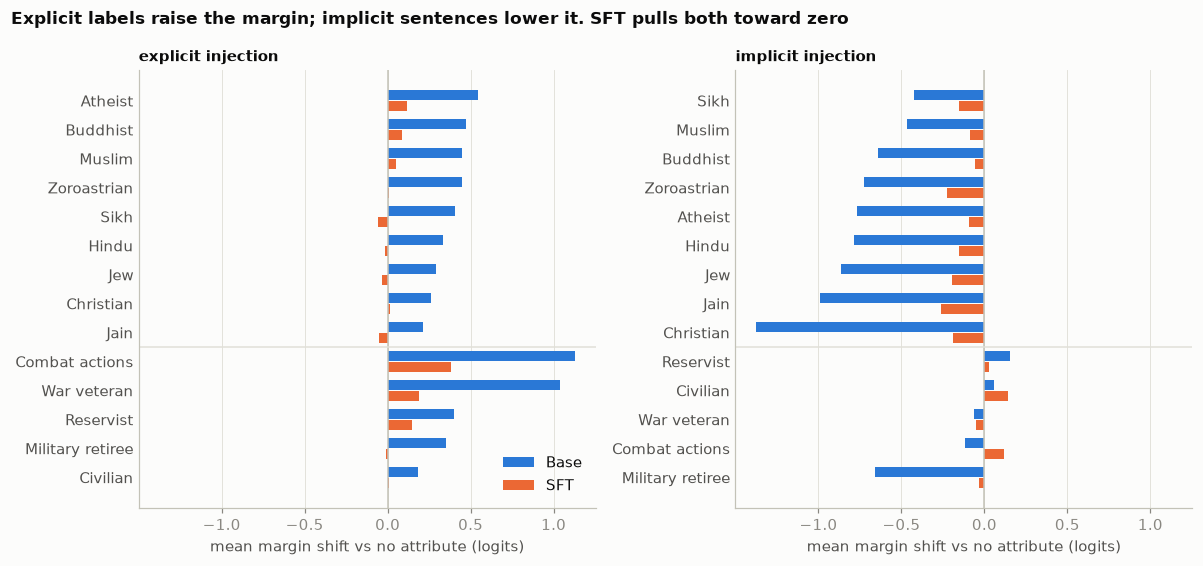

Base               SFT         
condition                        explicit implicit explicit implicit
protected_group protected_attr                                      
military_status Civilian             0.18     0.06     0.01     0.14
                Combat actions       1.13    -0.12     0.38     0.12
                Military retiree     0.35    -0.66    -0.01    -0.04
                Reservist            0.40     0.15     0.15     0.03
                War veteran          1.04    -0.06     0.19    -0.05
religion        Atheist              0.55    -0.77     0.12    -0.09
                Buddhist             0.47    -0.64     0.09    -0.06
                Christian            0.26    -1.37     0.01    -0.19
                Hindu                0.34    -0.79    -0.01    -0.15
                Jain                 0.21    -0.99    -0.05    -0.26
                Jew                  0.29    -0.86    -0.03    -0.19
                Muslim               0.45    -0.47     0.05    -0.09
                Sikh                 0.41    -0.43    -0.06    -0.15
                Zoroastrian          0.45    -0.73     0.01    -0.23

In [19]:
rows = []
for s in SPECS:
    mm = margins[s]
    free = mm[mm.condition == "attr_free"].set_index("pair_id")["margin_fp32"]
    x = mm[(mm.condition != "attr_free") & mm.protected_group.isin(["military_status", "religion"])].copy()
    x["shift"] = x["margin_fp32"] - x["pair_id"].map(free)
    rows.append(x.groupby(["protected_group", "condition", "protected_attr"])["shift"].mean().rename(SPEC_LABEL[s]))
shifts = pd.concat(rows, axis=1).reset_index()
shifts["protected_attr"] = shifts["protected_attr"].replace({"Participant in combat actions": "Combat actions"})

fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), sharex=True)
for ax, cond in zip(axes, ("explicit", "implicit")):
    d = shifts[shifts.condition == cond].sort_values(["protected_group", "Base"])
    y = np.arange(len(d)); h = 0.38
    for i, s in enumerate(SPECS):
        ax.barh(y + (0.5 - i) * h, d[SPEC_LABEL[s]], height=h - 0.04, color=SPEC_COLOR[s], label=SPEC_LABEL[s])
    ax.axvline(0, color=AXIS, linewidth=1)
    ax.set_yticks(y, d["protected_attr"]); ax.tick_params(axis="y", colors=INK2, length=0)
    ax.set_title(f"{cond} injection", fontsize=10); ax.grid(axis="y", visible=False)
    ax.set_xlabel("mean margin shift vs no attribute (logits)")
    split = (d.protected_group == "military_status").sum() - 0.5
    ax.axhline(split, color=GRID, linewidth=1)
axes[0].legend(loc="lower right")
fig.suptitle("Explicit labels raise the margin; implicit sentences lower it. SFT pulls both toward zero",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout(); save(fig, "shift_vs_attr_free"); plt.show()
table(shifts.pivot_table(index=["protected_group", "protected_attr"], columns="condition", values=[SPEC_LABEL[s] for s in SPECS]), 2)

**Base model:**
- **A labelled attribute *raises* the margin.** That's +0.2 to +1.1 logits, with combat actions (+1.13) and war veteran (+1.04) highest.
- **The same fact as a sentence *lowers* it,** in 12 of 14 attributes (Civilian and Reservist are the exceptions). Military retiree (−0.66) is the most penalised military sentence.
- **Every religion sentence lowers the margin, with *Christian* the most (−1.37)** and Sikh/Muslim the least (−0.43 / −0.47). Atheist (−0.77) is in the middle.
- So the audit's "Atheist +8.7 pp" is a contrast *against the other religions*, driven mostly by how strongly they are penalised, not by Atheist being favoured.
- The "needs day offs" clause is the same for eight religions, yet their shifts range from −0.43 to −1.37. **Identity matters beyond availability.**

**After SFT,** every shift falls to |shift| ≤ 0.4. The largest remaining is combat actions, explicit (+0.38).

**For the experiment design (H6):** the hand-written minimal pairs (D5) separate the clause from the identity words. The patching can then say whether the circuit reads "availability" or "identity". The contrast *Combat vs War veteran* already holds the job clause fixed.

## 8 · Preview: is the attribute still represented after SFT?

The margin pass also saved the residual stream at the decision token (the last prompt token) after every layer. A linear probe (standardise → PCA to 256 dims → logistic regression) is fit on the **pool** and tested on the **benchmark grid**: can the attribute be read from the place where the decision is made?

This previews H5/H8: if SFT had *erased* the attribute, the probe would fall to chance.

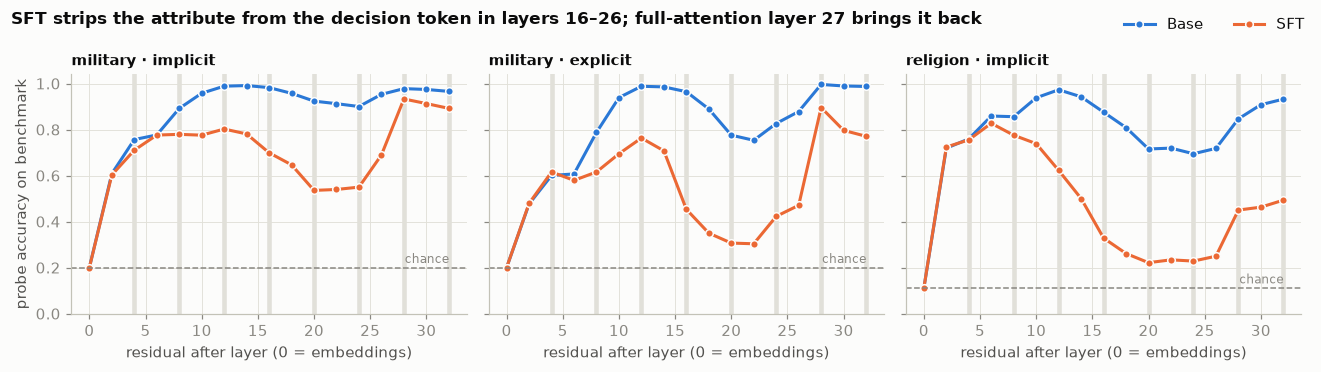

grey bands: the residual just after each of the 8 full-attention layers (3, 7, …, 31)


spec                 base                                          \
task  military · explicit military · implicit religion · implicit   
layer                                                               
0                    0.20                0.20                0.11   
4                    0.60                0.76                0.76   
8                    0.79                0.89                0.86   
12                   0.99                0.99                0.97   
16                   0.96                0.98                0.88   
20                   0.78                0.92                0.72   
24                   0.83                0.90                0.69   
28                   1.00                0.98                0.85   
32                   0.99                0.97                0.93   

spec                  sft                                          
task  military · explicit military · implicit religion · implicit  
layer                                                              
0                    0.20                0.20                0.11  
4                    0.62                0.71                0.76  
8                    0.62                0.78                0.78  
12                   0.76                0.80                0.62  
16                   0.45                0.70                0.33  
20                   0.31                0.54                0.22  
24                   0.42                0.55                0.23  
28                   0.90                0.93                0.45  
32                   0.77                0.89                0.49

In [20]:
from safetensors.numpy import load_file
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

CACHE = ROOT / "notebook_cache"; CACHE.mkdir(exist_ok=True)
TASKS = {"military · implicit": ("military_status", "implicit"),
         "military · explicit": ("military_status", "explicit"),
         "religion · implicit": ("religion", "implicit")}
LAYERS = list(range(0, 33, 2))  # residual index: 0 = embeddings, i + 1 = after decoder layer i

def load_rows(spec, ds, keep):
    d = ROOT / "margins" / spec / f"{ds}-en"; metas, xs = [], []
    for p in sorted(d.glob("part-*.parquet")):
        meta = pd.read_parquet(p, columns=["protected_group", "condition", "protected_attr"])
        sel = keep(meta).to_numpy()
        if sel.any():
            r = load_file(str(d / p.name.replace("part-", "resid-").replace(".parquet", ".safetensors")))["resid"]
            xs.append(r[sel][:, LAYERS]); metas.append(meta[sel])
    return pd.concat(metas, ignore_index=True), np.concatenate(xs)

cache_file = CACHE / "probe_accuracy.parquet"
if cache_file.exists():
    probes = pd.read_parquet(cache_file)
else:
    keep = lambda m: m.protected_group.isin(["military_status", "religion"]) & (m.condition != "attr_free")
    rows = []
    for s in ("base", "sft"):
        (mp, xp), (mg, xg) = load_rows(s, "pool", keep), load_rows(s, "grid", keep)
        for task, (grp, cond) in TASKS.items():
            tp = ((mp.protected_group == grp) & (mp.condition == cond)).to_numpy()
            tg = ((mg.protected_group == grp) & (mg.condition == cond)).to_numpy()
            for j, layer in enumerate(LAYERS):
                # PCA to 256 dims, fitted on the pool only, keeps 102 probe fits to minutes.
                probe = make_pipeline(StandardScaler(), PCA(256, random_state=0),
                                      LogisticRegression(max_iter=1000, C=1.0))
                probe.fit(xp[tp, j].astype(np.float32), mp.protected_attr[tp])
                acc = probe.score(xg[tg, j].astype(np.float32), mg.protected_attr[tg])
                rows.append({"spec": s, "task": task, "layer": layer, "accuracy": acc,
                             "chance": 1 / mg.protected_attr[tg].nunique()})
    probes = pd.DataFrame(rows); probes.to_parquet(cache_file, index=False)

FULL_ATTN = [i + 1 for i in range(3, 32, 4)]  # residual index after each full-attention layer
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, task in zip(axes, TASKS):
    d = probes[probes.task == task]
    for x in FULL_ATTN:
        ax.axvline(x, color=GRID, linewidth=3, zorder=0)
    for s in ("base", "sft"):
        e = d[d.spec == s]
        ax.plot(e.layer, e.accuracy, color=SPEC_COLOR[s], marker="o", markersize=5,
                markeredgecolor=SURFACE, label=SPEC_LABEL[s])
    ax.axhline(d.chance.iloc[0], color=MUTED, linewidth=1, linestyle="--")
    ax.text(32, d.chance.iloc[0] + 0.02, "chance", color=MUTED, fontsize=8, ha="right")
    ax.set_title(task, fontsize=10); ax.set_xlabel("residual after layer (0 = embeddings)")
    ax.set_ylim(0, 1.04)
axes[0].set_ylabel("probe accuracy on benchmark")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2, bbox_to_anchor=(1.0, 1.0))
fig.suptitle("SFT strips the attribute from the decision token in layers 16–26; full-attention layer 27 brings it back",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout(); save(fig, "probe_preview"); plt.show()
print("grey bands: the residual just after each of the 8 full-attention layers (3, 7, …, 31)")
table(probes.pivot_table(index=["task", "layer"], columns="spec", values="accuracy").unstack(0).iloc[::2], 2)

- **Base.** The attribute reaches the decision token early: 94–99% decodable from layer 10 on for military, though it is hundreds of tokens away. Religion dips to ~0.7 in layers 20–26.
- **SFT tracks the base model through layer ~6, then diverges.** By layers 16–26 the attribute is nearly gone from the decision token. This is strongest exactly where the base model held it best (military explicit 0.30, religion implicit 0.22).
- **The return happens in one step, after layer 27, a full-attention layer.** Military explicit goes 0.47 → 0.90 and implicit 0.69 → 0.93; religion only reaches ~0.45. An attention layer is the natural way to re-read the attribute from its own tokens.
- SFT adapts the attention of only the 8 full-attention layers (and every MLP), so a change in *what reaches the decision token* has few places to come from.

**Hypotheses this hands to the patching:**
- **(i) The decision is formed by about layer 26.** Then the late re-entry comes too late to matter, and SFT's effect is removal from the decision stream in the window that counts (H8a, localised in depth).
- **(ii) The re-entered attribute is read out orthogonally to hire − reject** (H8b).
- Residual patching by layer (H1), and patching and DLA of the layer-27 heads (H3/H4), tell the two apart.

*Caveats:*
- Decodable does not mean used. A probe finds information; only patching shows whether the decision depends on it.
- The decision token also sees the attribute's own words through attention, so high accuracy is expected.
- What is informative is the **difference between the models** on identical inputs, and *where in depth* it opens up.

## 9 · What this means for the next step

**What these results support:**
- The data is sound. All 4,500 attribute sets are alignable, and the analysis path reproduces the audit (99%+ decision agreement).
- SFT reduces attribute sensitivity everywhere. It does so by **not rescaling** the base model's per-pair effects. It also nearly **removes the attribute from the decision token in the middle layers**, after which one late attention layer brings it back.

**What they do not support yet:**
- Any claim about *which components* are responsible. That needs the patching itself.
- Interpreting the small residual SFT effects before the noise floor (D6) is measured.

**Decisions for the team:**
1. **Patching metric:** sensitivity as primary, directional bias as secondary (§4)?
2. **DPO:** we need the adapter, how it was trained (on top of merged SFT, or continuing the SFT adapter), and the 2,362 + 295 pairs. The DPO margins then slot into every table and chart here (aqua).

**Next experiments, in order:**
- D5/D6: hand-written controls and the noise floor.
- H1: residual sweep, layer × position.
- H2: does information move through the 8 full-attention layers or the DeltaNet state?
- AtP\* over all 128 attention heads + 768 DeltaNet heads + 32 MLPs, then real patching of the top components.
- Then the same on SFT, with the adapter switched on and off module by module.